In [20]:
import os
from typing import TypedDict
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

In [21]:
load_dotenv()  # take environment variables from .env.

True

In [22]:
load_dotenv(override=True)  # Load credentials from the project .env file.

google_api_key = os.getenv("GOOGLE_API_KEY")
if not google_api_key:
    raise ValueError(
        "Set GOOGLE_API_KEY in .env to a valid Google AI Studio API key; "
        "do not use an OAuth access token."
    )

In [23]:
primary = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=google_api_key,
    max_retries=3,
)
backup = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    max_retries=3,
)

model = primary.with_fallbacks([backup])

parent_llm = model
subgraph_llm = model

In [24]:
class ParentState(TypedDict):
    question: str
    answer_eng: str
    answer_hin: str


In [25]:
def translate_text(state: ParentState):

    prompt = f"""
Translate the following text to Hindi.
Keep it natural and clear. Do not add extra content.

Text:
{state["answer_eng"]}
""".strip()
    
    translated_text = subgraph_llm.invoke(prompt).content

    return {'answer_hin': translated_text}

In [26]:
subgraph_builder = StateGraph(ParentState)
subgraph_builder.add_node("translate_text", translate_text)
subgraph_builder.add_edge(START, "translate_text")
subgraph_builder.add_edge("translate_text", END)

subgraph = subgraph_builder.compile()

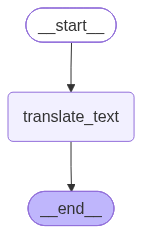

In [27]:
subgraph

In [28]:
def generate_answer(state: ParentState):

    answer = parent_llm.invoke(f"You are a helpful assistant. Answer clearly.\n\nQuestion: {state['question']}").content
    return {'answer_eng': answer}

In [29]:
parent_builder = StateGraph(ParentState)

parent_builder.add_node("answer", generate_answer)
parent_builder.add_node("translate", subgraph)

parent_builder.add_edge(START, 'answer')
parent_builder.add_edge('answer', 'translate')
parent_builder.add_edge('translate', END)

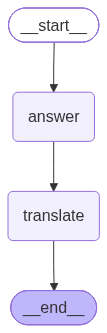

In [30]:
graph = parent_builder.compile()
graph

In [31]:
graph.invoke({'question': 'What is quantum physics'})

{'question': 'What is quantum physics',
 'answer_eng': [{'type': 'text',
   'text': '**Quantum physics** (also known as quantum mechanics) is the branch of science that studies matter and energy at the smallest possible scales—specifically, at the level of atoms and subatomic particles (like electrons, protons, and photons).\n\nIn our everyday world, objects follow the rules of **classical physics** (the laws described by scientists like Isaac Newton). For example, if you throw a baseball, you can easily predict where it will land. \n\nHowever, at the atomic level, classical physics stops working. Particles behave in strange, counter-intuitive ways. \n\nHere are the key principles that make quantum physics different:\n\n### 1. Quantization (Energy in "Packets")\nIn classical physics, energy flows smoothly like a ramp. In quantum physics, energy changes in fixed, microscopic steps—like climbing a staircase. These individual "steps" or packets of energy are called **quanta** (the plural 